The source code is in the public domain and not licensed or under copyright. The information and software may be used freely by the public. As required by 17 U.S.C. 403, third parties producing copyrighted works consisting predominantly of the material produced by U.S. government agencies must provide notice with such work(s) identifying the U.S. Government material incorporated and stating that such material is not subject to copyright protection.

Derived works shall not identify themselves in a manner that implies an endorsement by or an affiliation with the Naval Research Laboratory.

RECIPIENT BEARS ALL RISK RELATING TO QUALITY AND PERFORMANCE OF THE SOFTWARE AND ANY RELATED MATERIALS, AND AGREES TO INDEMNIFY THE NAVAL RESEARCH LABORATORY FOR ALL THIRD-PARTY CLAIMS RESULTING FROM THE ACTIONS OF RECIPIENT IN THE USE OF THE SOFTWARE.

In [7]:
import numpy as np
from scipy.optimize import brentq
from scipy import constants as C
from matplotlib import pyplot as plt

In [8]:
L = .1 # length of flying focus
R = .02 # radius of fresnel lens
z0 = 0.2 # distance from lens to flying focus starting point
nrefr = 1.5
vel = .999*C.c # velocity of flying focus
grooves = 8 # how many grooves in fresnel lens
b = R/grooves # groove separation

# in the following m indexes the grooves
def merit(q,m):
    '''root is the angle of incidence (same as sawtooth angle)'''
    return np.tan(np.arcsin(nrefr*np.sin(q)) - q) - (m+0.5)*b/(z(m)-b*np.tan(q)/2)

def r0(m):
    '''radii where sawtooth peaks occur'''
    return m*b
def q(m):
    '''angle of sawtooth'''
    return brentq(merit,0,0.5,args=(m,))
def a(m):
    '''height of sawtooth'''
    return b*np.tan(q(m))
def z(m):
    '''focal point of rays that pass through sawtooth midpoint'''
    return z0 + L*r0(m+0.5)/R
def fresnel_delay(m):
    '''delay from base of fresnel lens to focal point'''
    return (nrefr*a(m)/2 + np.sqrt(r0(m+0.5)**2 + (z(m)-a(m)/2)**2))/C.c
def echelon_height(r):
    m = int(r/b)
    return C.c*L*r0(m+0.5)/(vel*R) - C.c*fresnel_delay(m)
def fresnel_height(r):
    m = int(r/b)
    dr = r - m*b
    return a(m)*(b-dr)/b

Text(0, 0.5, 'h ($\\mu$m)')

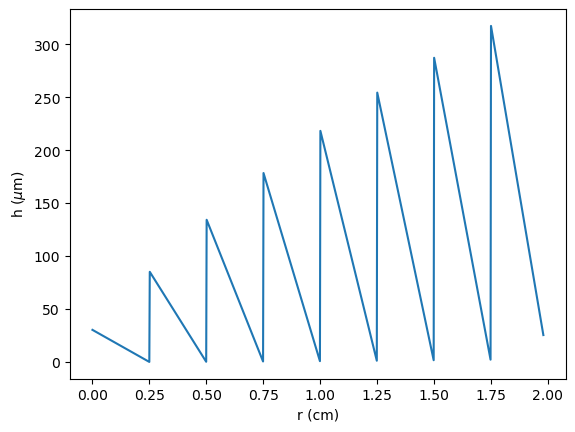

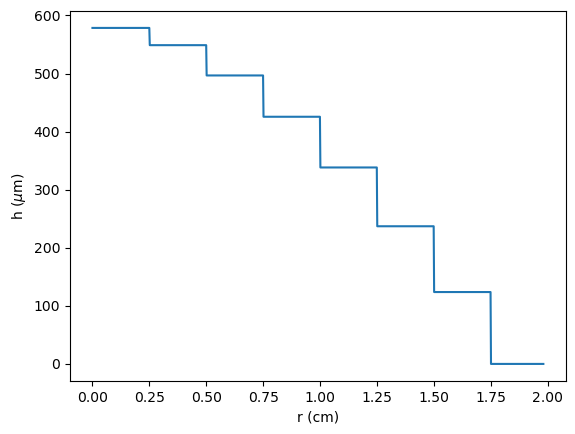

In [9]:
rlist = np.linspace(0,0.99*R,1000)
hlist = np.array([fresnel_height(r) for r in rlist])
plt.plot(rlist*100,hlist*1e6)
plt.xlabel('r (cm)')
plt.ylabel('h ($\mu$m)')

plt.figure()
echlist = np.array([echelon_height(r) for r in rlist])
echlist -= np.min(echlist)
plt.plot(rlist*100,echlist*1e6)
plt.xlabel('r (cm)')
plt.ylabel('h ($\mu$m)')